## drug drug interaction

In [74]:
#import libraries
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
#download data
path = kagglehub.dataset_download("mghobashy/drug-drug-interactions")

In [76]:
#read data
ddi = pd.read_csv(os.path.join(path, "db_drug_interactions.csv"))

In [77]:
#show
ddi.head()

,Drug 1,Drug 2,Interaction Description
0,Trioxsalen,Verteporfin,Trioxsalen may increase the photosensitizing a...
1,Aminolevulinic acid,Verteporfin,Aminolevulinic acid may increase the photosens...
2,Titanium dioxide,Verteporfin,Titanium dioxide may increase the photosensiti...
3,Tiaprofenic acid,Verteporfin,Tiaprofenic acid may increase the photosensiti...
4,Cyamemazine,Verteporfin,Cyamemazine may increase the photosensitizing ...


In [78]:
#data info
ddi.info()

<class 'pandas.DataFrame'>
RangeIndex: 191541 entries, 0 to 191540
Data columns (total 3 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   Drug 1                   191541 non-null  str  
 1   Drug 2                   191541 non-null  str  
 2   Interaction Description  191541 non-null  str  
dtypes: str(3)
memory usage: 4.4 MB


In [79]:
#find nulls
ddi.isnull().sum()

Drug 1                     0
Drug 2                     0
Interaction Description    0
dtype: int64

In [80]:
#clean columns
for col in ddi:
    ddi[col] = ddi[col].astype(str).str.strip().str.lower()

In [81]:
#drop duplicates
ddi = ddi.drop_duplicates(subset=['Drug 1', 'Drug 2'], keep='first')

In [82]:
#detrmine the number of interactions for each drug
all_drugs = pd.concat([ddi["Drug 1"], ddi["Drug 2"]], ignore_index=True)
drug_degree = all_drugs.value_counts()

print(drug_degree.describe())

count    1701.000000
mean      224.870076
std       195.607618
min         1.000000
25%        58.000000
50%       183.000000
75%       352.000000
max       912.000000
Name: count, dtype: float64


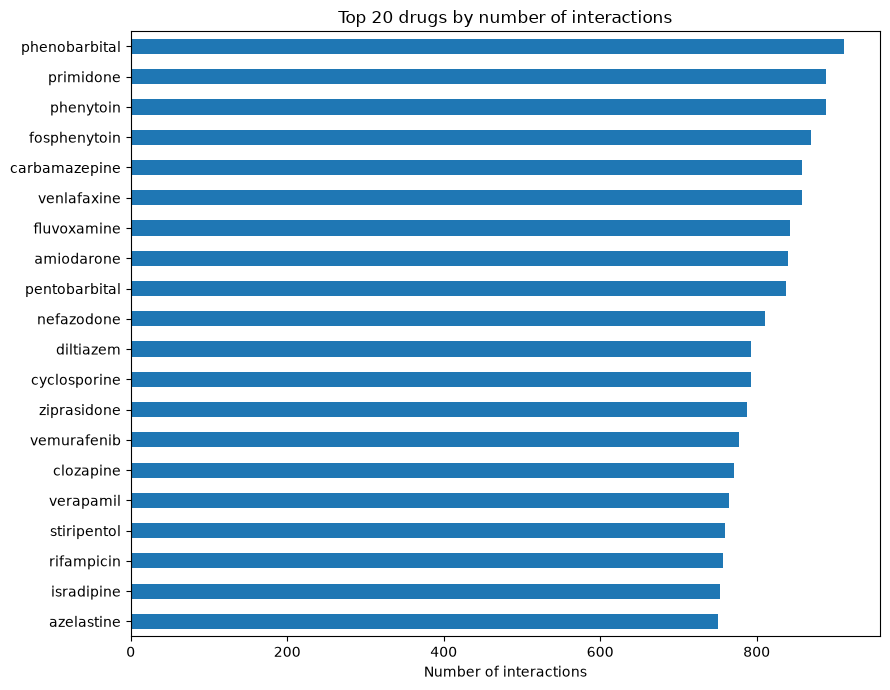

In [83]:
#find top 20 drugs by number of interactions
fig, ax = plt.subplots(figsize=(9, 7))
drug_degree.head(20).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 20 drugs by number of interactions")
ax.set_xlabel("Number of interactions")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

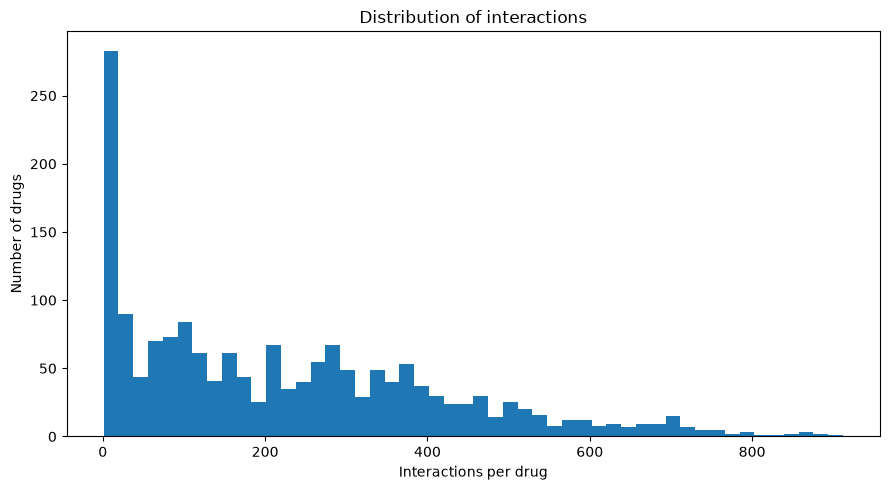

In [ ]:
#find the distribution of each interaction for all drugs
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(drug_degree.values, bins=50)
ax.set_title("Distribution of interactions")
ax.set_xlabel("Interactions per drug")
ax.set_ylabel("Number of drugs")
plt.tight_layout()
plt.show()

In [ ]:
#save cleaned data
ddi.to_csv("../data/ddi_clean.csv", index=False)

## Key Findings

* **Data size:** 191,541 interaction records reduced to 170,100 after removing duplicates, covering 1,701 unique drugs.
* **Missing values:** 0 missing values across all columns (Drug 1, Drug 2, and Interaction Description).
* **Interaction distribution:** highly right-skewed; the average is 224.87 interactions per drug (±195.6), ranging from 1 to 912.
* **Distribution spread:** 50% of drugs have 183 or fewer interactions, while 75% have up to 352.
* **Top interaction hubs:** a small group of drugs acts as major hubs with up to 912 interactions.